# Customer Query Classification

## Objective
Develop a machine learning model that classifies customer queries
into five predefined categories.


In [1]:

import pandas as pd
import numpy as np

df = pd.read_csv("/content/customer_support_dataset.csv")

print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())

display(df.head())


Dataset shape: (25635, 4)

Columns: ['query', 'category', 'intent', 'source']


,query,category,intent,source
0,question about cancelling order {{Order Number}},Refund & Cancellation,cancel_order,Bitext
1,i have a question about cancelling oorder {{Or...,Refund & Cancellation,cancel_order,Bitext
2,i need help cancelling puchase {{Order Number}},Refund & Cancellation,cancel_order,Bitext
3,I need to cancel purchase {{Order Number}},Refund & Cancellation,cancel_order,Bitext
4,"I cannot afford this order, cancel purchase {{...",Refund & Cancellation,cancel_order,Bitext


In [2]:

print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Queries:")
print(df["query"].duplicated().sum())

print("\nCategory Distribution:")
print(df["category"].value_counts())

print("\nUnique Categories:")
print(df["category"].unique())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25635 entries, 0 to 25634
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   query     25635 non-null  object
 1   category  25635 non-null  object
 2   intent    25635 non-null  object
 3   source    25635 non-null  object
dtypes: object(4)
memory usage: 801.2+ KB

Missing Values:
query       0
category    0
intent      0
source      0
dtype: int64

Duplicate Queries:
0

Category Distribution:
category
General Inquiry          7824
Technical Support        6442
Order Status             6304
Refund & Cancellation    4065
Product Inquiry          1000
Name: count, dtype: int64

Unique Categories:
['Refund & Cancellation' 'Order Status' 'General Inquiry'
 'Technical Support' 'Product Inquiry']


## Text preprocessing

In [3]:

import re

def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r"\s+", " ", text)
    text = re.sub(r"[^\w\s]", " ", text)
    return text.strip()

df["clean_query"] = df["query"].apply(preprocess_text)

display(df[["query", "clean_query"]].head(10))


,query,clean_query
0,question about cancelling order {{Order Number}},question about cancelling order order number
1,i have a question about cancelling oorder {{Or...,i have a question about cancelling oorder or...
2,i need help cancelling puchase {{Order Number}},i need help cancelling puchase order number
3,I need to cancel purchase {{Order Number}},i need to cancel purchase order number
4,"I cannot afford this order, cancel purchase {{...",i cannot afford this order cancel purchase ...
5,can you help me cancel order {{Order Number}}?,can you help me cancel order order number
6,"I can no longer afford order {{Order Number}},...",i can no longer afford order order number ...
7,I am trying to cancel purchase {{Order Number}},i am trying to cancel purchase order number
8,I have got to cancel purchase {{Order Number}},i have got to cancel purchase order number
9,i need help canceling purchase {{Order Number}},i need help canceling purchase order number


## Train-test split

In [4]:

from sklearn.model_selection import train_test_split

X = df["clean_query"]
y = df["category"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining distribution:")
print(y_train.value_counts())

print("\nTesting distribution:")
print(y_test.value_counts())


Training samples: 20508
Testing samples: 5127

Training distribution:
category
General Inquiry          6259
Technical Support        5154
Order Status             5043
Refund & Cancellation    3252
Product Inquiry           800
Name: count, dtype: int64

Testing distribution:
category
General Inquiry          1565
Technical Support        1288
Order Status             1261
Refund & Cancellation     813
Product Inquiry           200
Name: count, dtype: int64


## TF-IDF feature extraction

In [5]:

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training matrix:", X_train_tfidf.shape)
print("Testing matrix:", X_test_tfidf.shape)


Training matrix: (20508, 5298)
Testing matrix: (5127, 5298)


## Model 1: Logistic Regression

In [6]:

from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

lr_model.fit(X_train_tfidf, y_train)

lr_predictions = lr_model.predict(X_test_tfidf)

print("Logistic Regression training completed!")


Logistic Regression training completed!


## Model 2: Linear SVM

In [7]:

from sklearn.svm import LinearSVC

svm_model = LinearSVC(
    C=1.0,
    class_weight="balanced",
    random_state=42
)

svm_model.fit(X_train_tfidf, y_train)

svm_predictions = svm_model.predict(X_test_tfidf)

print("Linear SVM training completed!")


Linear SVM training completed!


## Model evaluation

In [8]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

def evaluate_model(name, y_true, predictions):

    print("\n", "=" * 50)
    print(name)
    print("=" * 50)

    print("Accuracy:",
          accuracy_score(y_true, predictions))

    print("Precision:",
          precision_score(y_true, predictions, average="macro"))

    print("Recall:",
          recall_score(y_true, predictions, average="macro"))

    print("F1-score:",
          f1_score(y_true, predictions, average="macro"))

    print("\nClassification Report:")
    print(classification_report(y_true, predictions))

evaluate_model(
    "Logistic Regression",
    y_test,
    lr_predictions
)

evaluate_model(
    "Linear SVM",
    y_test,
    svm_predictions
)



Logistic Regression
Accuracy: 0.9970743124634289
Precision: 0.9960336321379764
Recall: 0.9969833678539122
F1-score: 0.9964981576319566

Classification Report:
                       precision    recall  f1-score   support

      General Inquiry       1.00      1.00      1.00      1565
         Order Status       0.99      1.00      0.99      1261
      Product Inquiry       0.99      1.00      1.00       200
Refund & Cancellation       1.00      0.99      1.00       813
    Technical Support       1.00      1.00      1.00      1288

             accuracy                           1.00      5127
            macro avg       1.00      1.00      1.00      5127
         weighted avg       1.00      1.00      1.00      5127


Linear SVM
Accuracy: 0.9982445874780573
Precision: 0.9986104564261857
Recall: 0.9978733760374876
F1-score: 0.9982355037177688

Classification Report:
                       precision    recall  f1-score   support

      General Inquiry       1.00      1.00      1.00   

## Confusion matrices

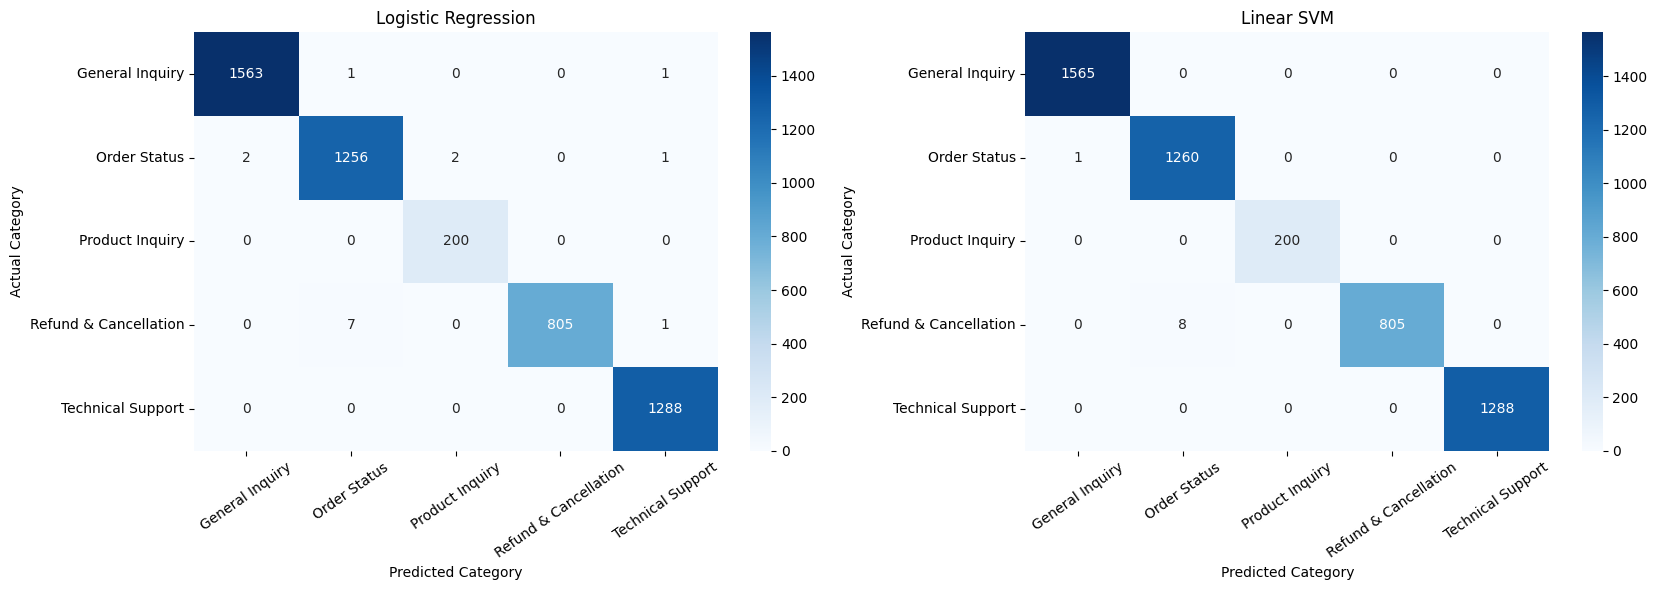

In [9]:

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

models = [
    ("Logistic Regression", lr_predictions),
    ("Linear SVM", svm_predictions)
]

for ax, (name, predictions) in zip(axes, models):

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=sorted(y.unique())
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=sorted(y.unique()),
        yticklabels=sorted(y.unique()),
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Category")
    ax.set_ylabel("Actual Category")
    ax.tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()


## Model comparison

In [10]:

results = []

for name, predictions in [
    ("Logistic Regression", lr_predictions),
    ("Linear SVM", svm_predictions)
]:

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, average="macro"
        ),
        "Recall": recall_score(
            y_test, predictions, average="macro"
        ),
        "F1-score": f1_score(
            y_test, predictions, average="macro"
        )
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by="F1-score",
        ascending=False
    )
)


,Model,Accuracy,Precision,Recall,F1-score
1,Linear SVM,0.998245,0.998610,0.997873,0.998236
0,Logistic Regression,0.997074,0.996034,0.996983,0.996498


## Test custom customer queries

In [11]:

test_queries = [
    "Where is my order currently?",
    "I want to cancel my purchase and get my money back.",
    "My application keeps crashing when I open it.",
    "What are the specifications of your laptop?",
    "How can I contact customer support?"
]

clean_queries = [
    preprocess_text(q) for q in test_queries
]

query_vectors = tfidf.transform(clean_queries)

# Select the best model based on macro F1
best_model_name = results_df.sort_values(
    "F1-score", ascending=False
).iloc[0]["Model"]

best_model = (
    lr_model if best_model_name == "Logistic Regression"
    else svm_model
)

predictions = best_model.predict(query_vectors)

for query, category in zip(test_queries, predictions):
    print("Query:", query)
    print("Predicted category:", category)
    print("-" * 50)


Query: Where is my order currently?
Predicted category: Order Status
--------------------------------------------------
Query: I want to cancel my purchase and get my money back.
Predicted category: Refund & Cancellation
--------------------------------------------------
Query: My application keeps crashing when I open it.
Predicted category: Technical Support
--------------------------------------------------
Query: What are the specifications of your laptop?
Predicted category: Product Inquiry
--------------------------------------------------
Query: How can I contact customer support?
Predicted category: General Inquiry
--------------------------------------------------


In [14]:

# Independent queries not used during training

independent_queries = [
    "Could you tell me what makes your laptop worth buying?",
    "Do you sell gaming laptops with expandable memory?",
    "I would like to know the available colours of your smartwatch.",
    "Is there any information about your latest tablet?",
    "What payment methods can I use to purchase a product?",
    "My parcel has not arrived yet.",
    "I received the wrong item in my package.",
    "The application closes whenever I try to log in.",
    "I want my money returned for a cancelled purchase.",
    "Can someone from your team help me?",
    "Where can I find my previous purchase details?",
    "I am unable to access my account.",
    "How long does it take to receive an order?",
    "Can I change the delivery address of my purchase?",
    "My refund has not appeared in my bank account."
]

independent_vectors = tfidf.transform(
    [preprocess_text(q) for q in independent_queries]
)

independent_predictions = best_model.predict(
    independent_vectors
)

for query, prediction in zip(
    independent_queries,
    independent_predictions
):
    print("Query:", query)
    print("Predicted:", prediction)
    print("-" * 60)


Query: Could you tell me what makes your laptop worth buying?
Predicted: Product Inquiry
------------------------------------------------------------
Query: Do you sell gaming laptops with expandable memory?
Predicted: General Inquiry
------------------------------------------------------------
Query: I would like to know the available colours of your smartwatch.
Predicted: Product Inquiry
------------------------------------------------------------
Query: Is there any information about your latest tablet?
Predicted: General Inquiry
------------------------------------------------------------
Query: What payment methods can I use to purchase a product?
Predicted: General Inquiry
------------------------------------------------------------
Query: My parcel has not arrived yet.
Predicted: Order Status
------------------------------------------------------------
Query: I received the wrong item in my package.
Predicted: Order Status
--------------------------------------------------------

## Save the trained model

In [12]:

import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(
    tfidf,
    "models/tfidf_vectorizer.pkl"
)

joblib.dump(
    best_model,
    "models/customer_query_classifier.pkl"
)

print("Models saved successfully!")


Models saved successfully!


In [13]:
from google.colab import files

files.download("models/tfidf_vectorizer.pkl")
files.download("models/customer_query_classifier.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>